ORIGINAL DATASET
Dataset Shape:
(10000, 31)

First 5 Rows:
   gender  age     country      city customer_segment  tenure_months  \
0    male   68  bangladesh    london              sme             22   
1  female   57      canada    sydney       individual              9   
2    male   24     germany  new york              sme             58   
3    male   49   australia     dhaka       individual             19   
4    male   65  bangladesh     delhi       individual             52   

  signup_channel contract_type  monthly_logins  weekly_active_days  ...  \
0            web       monthly              26                   7  ...   
1         mobile       monthly               7                   5  ...   
2            web        yearly              19                   5  ...   
3         mobile        yearly              34                   7  ...   
4            web       monthly              20                   6  ...   

   avg_resolution_time  complaint_type  csat_score  escal

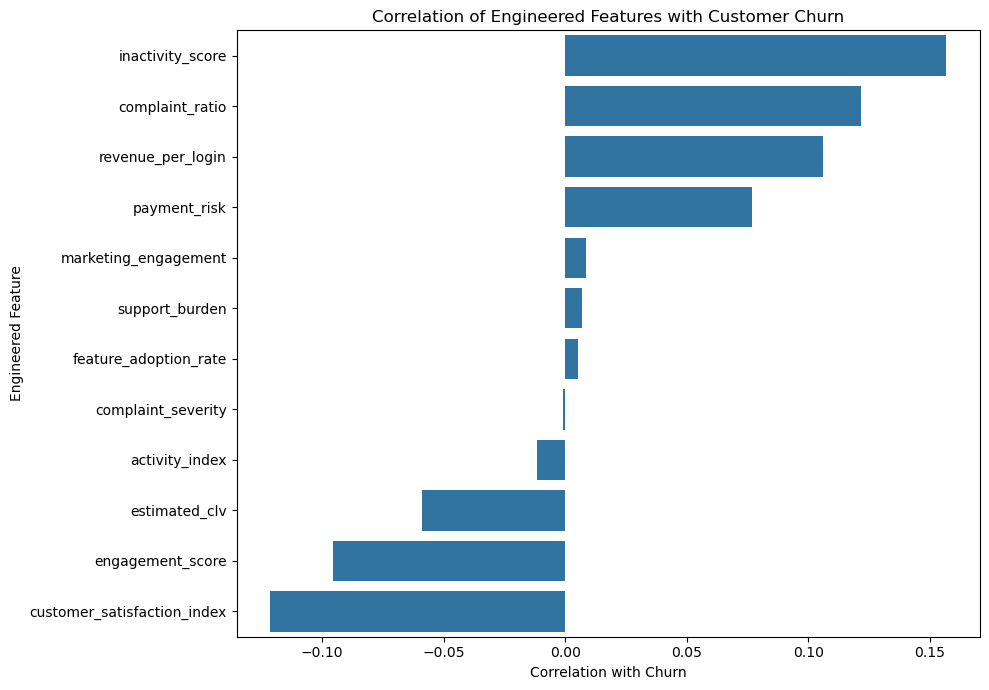


FINAL DATASET VALIDATION

Dataset Shape:
(10000, 45)

Total Missing Values:
0

Total Duplicate Rows:
0

Target Distribution:
churn
0    8979
1    1021
Name: count, dtype: int64

FEATURE ENGINEERING COMPLETED SUCCESSFULLY
Feature-engineered dataset saved as:
customer_churn_feature_engineered.csv

Final Dataset Shape: (10000, 45)


In [ ]:

# LIBRARIES

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns


# IMPORT CLEANED DATASET

CustomerData_Df = pd.read_csv(
"/Users/manesh/Library/CloudStorage/OneDrive-UniversityofPlymouth/Dissertation /Python_Code/customer_churn_cleaned.csv"
)

print("=" * 60)
print("ORIGINAL DATASET")
print("=" * 60)

print("Dataset Shape:")
print(CustomerData_Df.shape)

print("\nFirst 5 Rows:")
print(CustomerData_Df.head())

# INITIAL DATA VALIDATION

print("\n" + "=" * 60)
print("INITIAL DATA VALIDATION")
print("=" * 60)

print("\nMissing Values:")
print(CustomerData_Df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(CustomerData_Df.duplicated().sum())

print("\nTarget Distribution:")
print(CustomerData_Df["churn"].value_counts())

print("\nTarget Distribution (%):")
print(
(CustomerData_Df["churn"].value_counts(normalize=True) * 100)
.round(2)
)

# STANDARDISE CATEGORICAL VALUES

CustomerData_Df["price_increase_last_3m"] = (
CustomerData_Df["price_increase_last_3m"]
.astype("string")
.str.strip()
.str.title()
)

print("\nPrice Increase Categories:")
print(
CustomerData_Df["price_increase_last_3m"]
.value_counts(dropna=False)
)

# ESTIMATED CUSTOMER LIFETIME VALUE (CLV)

CustomerData_Df["estimated_clv"] = (
CustomerData_Df["monthly_fee"]
*
(CustomerData_Df["tenure_months"] + 12)
)


# CUSTOMER ENGAGEMENT SCORE

CustomerData_Df["engagement_score"] = (
CustomerData_Df["monthly_logins"] * 0.4
+
CustomerData_Df["weekly_active_days"] * 0.3
+
CustomerData_Df["features_used"] * 0.3
)

# CUSTOMER SUPPORT BURDEN
CustomerData_Df["support_burden"] = (
CustomerData_Df["support_tickets"]
+
(CustomerData_Df["escalations"] * 2)
)


# MARKETING ENGAGEMENT

CustomerData_Df["marketing_engagement"] = (
CustomerData_Df["email_open_rate"]
+
CustomerData_Df["marketing_click_rate"]
) / 2


# REVENUE PER LOGIN
    
CustomerData_Df["revenue_per_login"] = (
CustomerData_Df["monthly_fee"]
/
CustomerData_Df["monthly_logins"].replace(0, 1)
)


# COMPLAINT SEVERITY

CustomerData_Df["complaint_severity"] = (
CustomerData_Df["support_tickets"]
*
CustomerData_Df["avg_resolution_time"]
)


# CUSTOMER ACTIVITY INDEX

CustomerData_Df["activity_index"] = (
CustomerData_Df["weekly_active_days"]
*
CustomerData_Df["avg_session_time"]
)


# PAYMENT RISK SCORE

CustomerData_Df["payment_risk"] = (
CustomerData_Df["payment_failures"]
+
CustomerData_Df["price_increase_last_3m"].map({
"Yes": 2,
"No": 0
})
)


# CUSTOMER SATISFACTION INDEX


# ------------------------------------------------------------
# NPS Scaling
# ------------------------------------------------------------
CustomerData_Df["nps_scaled"] = (
CustomerData_Df["nps_score"] + 100
) / 200

# ------------------------------------------------------------
# CSAT Scaling
# ------------------------------------------------------------

CustomerData_Df["csat_scaled"] = (
CustomerData_Df["csat_score"] - 1
) / 4

# ------------------------------------------------------------
# Combined Satisfaction Index
# ------------------------------------------------------------

CustomerData_Df["customer_satisfaction_index"] = (
CustomerData_Df["csat_scaled"] * 0.5
+
CustomerData_Df["nps_scaled"] * 0.5
)


#  CUSTOMER INACTIVITY SCORE

CustomerData_Df["inactivity_score"] = (
CustomerData_Df["last_login_days_ago"]
/
(CustomerData_Df["tenure_months"] + 1)
)


# COMPLAINT RATIO

CustomerData_Df["complaint_ratio"] = (
CustomerData_Df["support_tickets"]
/
(CustomerData_Df["tenure_months"] + 1)
)


# FEATURE ADOPTION RATE

CustomerData_Df["feature_adoption_rate"] = (
CustomerData_Df["features_used"]
/
15
)


# LIST ENGINEERED FEATURES


new_features = [

"estimated_clv",

"engagement_score",

"support_burden",

"marketing_engagement",

"revenue_per_login",

"complaint_severity",

"activity_index",

"payment_risk",

"customer_satisfaction_index",

"inactivity_score",

"complaint_ratio",

"feature_adoption_rate"

]


# FEATURE ENGINEERING VALIDATION

print("\n" + "=" * 60)
print("ENGINEERED FEATURES")
print("=" * 60)

print("\nFirst 5 rows:")
print(
CustomerData_Df[new_features].head()
)


# FEATURE STATISTICS

print("\n" + "=" * 60)
print("ENGINEERED FEATURE STATISTICS")
print("=" * 60)

print(
CustomerData_Df[new_features]
.describe()
.T
.round(4)
)


# MISSING VALUE CHECK

print("\n" + "=" * 60)
print("ENGINEERED FEATURE MISSING VALUES")
print("=" * 60)

print(
CustomerData_Df[new_features]
.isnull()
.sum()
)


# INFINITE VALUE CHECK

print("\n" + "=" * 60)
print("INFINITE VALUE CHECK")
print("=" * 60)

numeric_new_features = CustomerData_Df[
new_features
].select_dtypes(include=np.number)

infinite_values = np.isinf(
numeric_new_features
).sum().sum()

print(
"Number of infinite values:",
infinite_values
)


# FEATURE RANGE VALIDATION

print("\n" + "=" * 60)
print("FEATURE RANGE VALIDATION")
print("=" * 60)

print("\nCSAT Scaled Range:")
print(
CustomerData_Df["csat_scaled"]
.agg(["min", "max"])
.round(4)
)

print("\nNPS Scaled Range:")
print(
CustomerData_Df["nps_scaled"]
.agg(["min", "max"])
.round(4)
)

print("\nFeature Adoption Rate Range:")
print(
CustomerData_Df["feature_adoption_rate"]
.agg(["min", "max"])
.round(4)
)


# ENGINEERED FEATURE CORRELATION WITH CHURN

print("\n" + "=" * 60)
print("CORRELATION OF ENGINEERED FEATURES WITH CHURN")
print("=" * 60)

feature_correlations = (
CustomerData_Df[
new_features + ["churn"]
]
.corr(numeric_only=True)["churn"]
.drop("churn")
.sort_values(
ascending=False
)
)

print(
feature_correlations.round(4)
)


# VISUALISE ENGINEERED FEATURE CORRELATIONS

plt.figure(
figsize=(10, 7)
)

sns.barplot(
x=feature_correlations.values,
y=feature_correlations.index
)

plt.title(
"Correlation of Engineered Features with Customer Churn"
)

plt.xlabel("Correlation with Churn")
plt.ylabel("Engineered Feature")

plt.tight_layout()
plt.show()


# FINAL DATASET VALIDATION


print("\n" + "=" * 60)
print("FINAL DATASET VALIDATION")
print("=" * 60)

print("\nDataset Shape:")
print(
CustomerData_Df.shape
)

print("\nTotal Missing Values:")
print(
CustomerData_Df.isnull().sum().sum()
)

print("\nTotal Duplicate Rows:")
print(
CustomerData_Df.duplicated().sum()
)

print("\nTarget Distribution:")
print(
CustomerData_Df["churn"].value_counts()
)


# SAVE FEATURE-ENGINEERED DATASET

CustomerData_Df.to_csv(
"customer_churn_feature_engineered.csv",
index=False
)


# COMPLETION MESSAGE

print("\n" + "=" * 60)
print("FEATURE ENGINEERING COMPLETED SUCCESSFULLY")
print("=" * 60)

print(
"Feature-engineered dataset saved as:"
)

print(
"customer_churn_feature_engineered.csv"
)

print(
"\nFinal Dataset Shape:",
CustomerData_Df.shape
)
